# 05b — Energy landscape and descent animation

Explore a designed two-dimensional energy surface. Compare trajectories from different starting points and step sizes, and export an animation. The surface is an illustrative function, not an inferred brain landscape. Numerical descent can overshoot when the step is too large.

Section references in the suggested reading refer to the [August background paper](../../paper/background/august-perspective.pdf). For the current talk, use the [slide-to-resource guide](../../talk/resources.md).


In [1]:
import os
from pathlib import Path
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np

REPO = os.environ.get("BRAINSMODELS_REPO_URL",
                      "https://github.com/arvidl/brains-to-models-publication.git")
COLAB_ROOT = Path("/content/brains-to-models")

if "google.colab" in sys.modules:
    if not (COLAB_ROOT / "code" / "src" / "brainsmodels").is_dir():
        subprocess.check_call(["git", "clone", "--depth", "1", REPO, str(COLAB_ROOT)])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ipympl"])
    root = COLAB_ROOT
else:
    here = Path.cwd().resolve()
    root = here.parents[1] if here.name == "notebooks" else here

src = root / "code" / "src"
if str(src) not in sys.path:
    sys.path.insert(0, str(src))

from brainsmodels.repro import DEFAULT_SEED, set_seed
from brainsmodels.landscape import (
    DEFAULT_START,
    descend,
    energy,
    explore_descent,
    render_paper_figure,
    write_animation,
    write_figure,
)

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})
print("repo root:", root)
print("seed:", SEED)

repo root: CHECKOUT
seed: 7


## A designed surface, not a measured brain

Two coordinates $(x,y)$ stand in for a slice of activity space. The energy is a handful of sines plus a weak quadratic bowl — enough wells to look like a landscape, few enough to read:

$$
U(x,y)=(\sin x+\sin\tfrac12 x)\cos y+(\cos\tfrac32 x+\cos\tfrac34 x)\sin\tfrac12 y+0.1(x^2+y^2).
$$

Gradient descent $ \mathbf{X}\leftarrow\mathbf{X}-\eta\nabla U $ is the yellow path. The well it reaches is an attractor: a memory, a percept, a decision — *in the schematic*. The ambient space of a cortex is not $\mathbb{R}^2$. The function is not fit to data.

In [2]:
path = descend(start=DEFAULT_START)
z = energy(path[:, 0], path[:, 1])
print(f"start {path[0]}  U={float(z[0]):+.3f}")
print(f"end   {path[-1]}  U={float(z[-1]):+.3f}")
print(f"steps {len(path)}  ΔU={float(z[-1] - z[0]):+.3f}")

start [0.8 4.8]  U=+3.267
end   [2.119 2.85 ]  U=-1.398
steps 59  ΔU=-4.666


## Paper figure

The static view for §6. Caption and title state exactly what it is: a 2-D slice, a designed $U$, one descent.

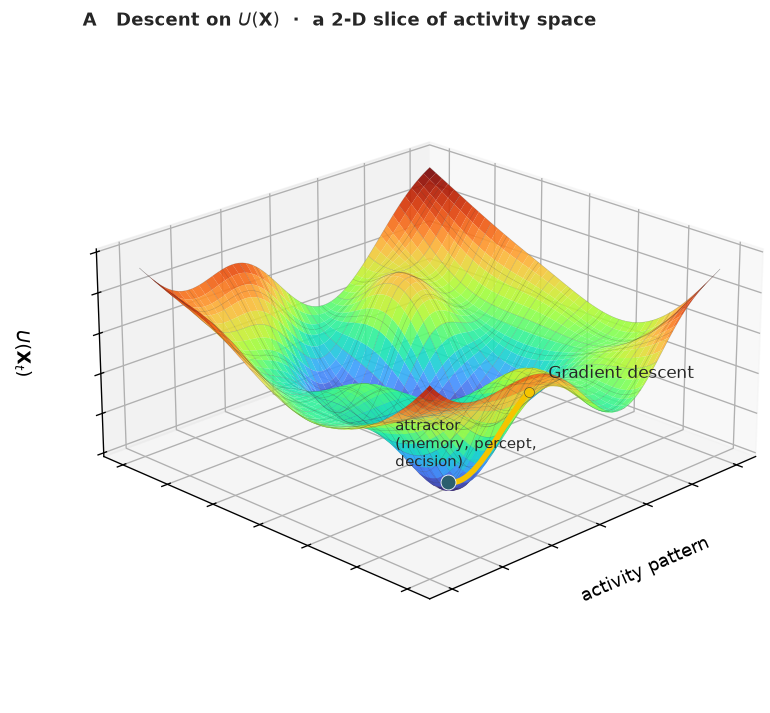

wrote CHECKOUT/paper/figures/energy_landscape.pdf
wrote CHECKOUT/paper/figures/energy_landscape.png


PosixPath('CHECKOUT/paper/figures/energy_landscape.pdf')

In [3]:
fig = render_paper_figure(path)
plt.show()
write_figure(root / "paper" / "figures", path=path)

## Descent animation

The same path, drawn a step at a time. GIF always; MP4 if `ffmpeg` is on the `PATH`. Colab will write into the cloned repo under `/content`.

In [4]:
gif = write_animation(root / "code" / "animations")
print("animation:", gif)

wrote CHECKOUT/code/animations/energy_landscape.gif


wrote CHECKOUT/code/animations/energy_landscape.mp4  (/opt/homebrew/bin/ffmpeg)
animation: CHECKOUT/code/animations/energy_landscape.gif


## Compare starting points

Click the contour map or use the sliders to choose a start. Descent can reach different basins from different starts; it need not reach the geometrically nearest minimum.

The widget requires `ipywidgets` and `ipympl`. If clicking is unavailable, use the sliders.


HTML(value='<i>Click the contour to drop a start (green). The path ends at a red attractor. Drag the 3-D panel…

HTML(value='')

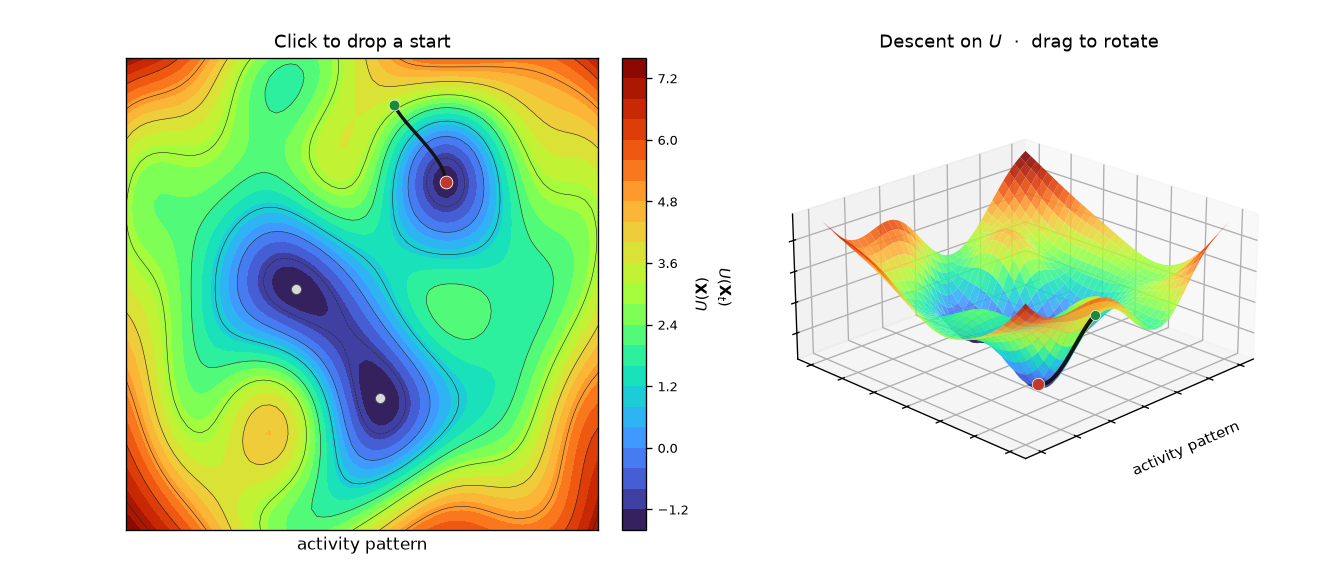

In [5]:
%matplotlib widget
explore_descent()

## Interpret the calculation

Describe the changes you observe under parameter or input interventions. Separate properties guaranteed by the equations from empirical behavior in this run and from biological interpretations.


### Exercises

1. **Nearby starts and basins.** Descend from (-2.50, -3.50) and (-2.18, -3.50). Which basin does each path enter? What measurements would be needed to test an analogous claim about a language model?

<!-- solution-box: 05b_1_nearby_starts_two_wells.py -->
<details>
<summary><strong>Show solution</strong> — Nearby starts and basins</summary>

Takes seconds on a laptop. Copy the block below into a new cell. From a clone of the repository, `%load ../solutions/05b_1_nearby_starts_two_wells.py` inserts the same code together with the few lines of setup it needs to run outside the notebook.

```python
"""Standalone solution; also %load-able from the companion notebook."""
from __future__ import annotations

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

try:
    _SRC = Path(__file__).resolve().parents[1] / "src"
except NameError:
    _cwd = Path.cwd().resolve()
    if (_cwd / "src" / "brainsmodels").is_dir():
        _SRC = _cwd / "src"
    elif (_cwd.parent / "src" / "brainsmodels").is_dir():
        _SRC = _cwd.parent / "src"
    else:
        _SRC = _cwd / "code" / "src"
if str(_SRC) not in sys.path:
    sys.path.insert(0, str(_SRC))

from brainsmodels.repro import DEFAULT_SEED, set_seed

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

from brainsmodels.landscape import ATTRACTORS, descend, energy, nearest_attractor
starts = ((-2.50, -3.50), (-2.18, -3.50), (0.80, 4.80))
print(f"{'start':<16}{'end':<16}{'U(end)':>8}  well")
for s in starts:
    path = descend(s)
    end = tuple(float(v) for v in path[-1])
    well = nearest_attractor(end, radius=0.6)
    print(f"{s!s:<16}{end!s:<16}{float(energy(*end)):>8.3f}  {well}")

print('Nearby starts can enter different basins on this chosen surface. Any analogy with prompt sensitivity needs independent model measurements.')
```

</details>
<!-- /solution-box -->


2. **Step size.** `descend` takes `lr`. From the default start, compare `lr=0.02` and `lr=0.25`: path length, final energy, and whether `nearest_attractor` still returns a listed well. When does a large step leave the teaching picture?

<!-- solution-box: 05b_2_step_size.py -->
<details>
<summary><strong>Show solution</strong> — Step size</summary>

Takes seconds on a laptop. Copy the block below into a new cell. From a clone of the repository, `%load ../solutions/05b_2_step_size.py` inserts the same code together with the few lines of setup it needs to run outside the notebook.

```python
"""Standalone solution; also %load-able from the companion notebook."""
from __future__ import annotations

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

try:
    _SRC = Path(__file__).resolve().parents[1] / "src"
except NameError:
    _cwd = Path.cwd().resolve()
    if (_cwd / "src" / "brainsmodels").is_dir():
        _SRC = _cwd / "src"
    elif (_cwd.parent / "src" / "brainsmodels").is_dir():
        _SRC = _cwd.parent / "src"
    else:
        _SRC = _cwd / "code" / "src"
if str(_SRC) not in sys.path:
    sys.path.insert(0, str(_SRC))

from brainsmodels.repro import DEFAULT_SEED, set_seed

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

from brainsmodels.landscape import DEFAULT_START, descend, energy, nearest_attractor
for lr in (0.02, 0.08, 0.25):
    path = descend(DEFAULT_START, lr=lr, n_steps=200)
    end = path[-1]
    well = nearest_attractor(tuple(end), radius=0.6)
    print(
        f"lr {lr:.2f}  steps {len(path):3d}  U={float(energy(*end)):+.3f}  "
        f"well {well}"
    )
print('Compare final energy and boundary clipping at each step size. These are numerical properties of the chosen two-dimensional potential.')
```

</details>
<!-- /solution-box -->


3. **Energy along the path.** Plot $U$ along the default descent. Is the sequence monotone? If a step rises, what in `descend` allowed it — and what would a true gradient flow have done?

<!-- solution-box: 05b_3_energy_along_the_path.py -->
<details>
<summary><strong>Show solution</strong> — Energy along the path</summary>

Takes seconds on a laptop. Copy the block below into a new cell. From a clone of the repository, `%load ../solutions/05b_3_energy_along_the_path.py` inserts the same code together with the few lines of setup it needs to run outside the notebook.

```python
"""Standalone solution; also %load-able from the companion notebook."""
from __future__ import annotations

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

try:
    _SRC = Path(__file__).resolve().parents[1] / "src"
except NameError:
    _cwd = Path.cwd().resolve()
    if (_cwd / "src" / "brainsmodels").is_dir():
        _SRC = _cwd / "src"
    elif (_cwd.parent / "src" / "brainsmodels").is_dir():
        _SRC = _cwd.parent / "src"
    else:
        _SRC = _cwd / "code" / "src"
if str(_SRC) not in sys.path:
    sys.path.insert(0, str(_SRC))

from brainsmodels.repro import DEFAULT_SEED, set_seed

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

from brainsmodels.landscape import DEFAULT_START, descend, energy
path = descend(DEFAULT_START)
u = np.array([float(energy(x, y)) for x, y in path])
ups = int(np.sum(np.diff(u) > 1e-9))
print(f"steps {len(path)}  ΔU {u[-1] - u[0]:+.3f}  uphill steps {ups}")

fig, ax = plt.subplots(figsize=(5.2, 3.0))
ax.plot(u)
ax.set_xlabel("descent step")
ax.set_ylabel("U(x, y)")
ax.set_title("Teaching descent on a plotted square")
plt.tight_layout()
plt.show()
print('A finite Euler step can increase energy when it overshoots. Check the step size and clipping before interpreting a nonmonotone path.')
```

</details>
<!-- /solution-box -->


### Questions for reflection

Use these questions to distinguish what the calculation shows from the assumptions and interpretations attached to it. Write an answer before consulting the instructor notes.


1. What does a valley in this drawing represent?

2. Why can a numerical descent step increase the energy?

3. What changes when the initial point changes?

4. What does the interactive view add?

5. What would be needed to infer a landscape from data?


### Further reading

These references provide background for the models and discussion. Distinguish primary experiments, reviews and commentary when using them as evidence. Section references follow the August background paper.

1. **Hopfield, J. J. (1982).** [*Neural networks and physical systems with emergent collective computational abilities*](https://redwood.berkeley.edu/wp-content/uploads/2018/08/hopfield82.pdf). *PNAS* 79(8), 2554–2558. Opened PDF.
2. **Ramsauer, H., et al. (2020).** [*Hopfield Networks is All You Need*](https://arxiv.org/abs/2008.02217). arXiv:2008.02217.
3. **Necker, L. A. (1832).** [*Observations on some remarkable optical phaenomena…*](https://en.wikipedia.org/wiki/Necker_cube). Entry via the opened Necker-cube page.
4. **Friston, K. (2010).** [*The free-energy principle: a unified brain theory?*](https://www.fil.ion.ucl.ac.uk/~karl/The%20free-energy%20principle%20A%20unified%20brain%20theory.pdf). *Nature Reviews Neuroscience* 11, 127–138. Author PDF.
5. **Doerig, A., et al. (2023).** [*The neuroconnectionist research programme*](https://konklab.fas.harvard.edu/Papers/Doerig_2023_NRN.pdf). *Nature Reviews Neuroscience* 24, 431–450.
